In [19]:
!pip -q install gdown streamlit
!gdown 14dS7ucQ2txS6se1ulPyjj2aMx0N7yTiM -O data_kemiskinan_sumut_2025.csv
!head -3 data_kemiskinan_sumut_2025.csv

Downloading...
From: https://drive.google.com/uc?id=14dS7ucQ2txS6se1ulPyjj2aMx0N7yTiM
To: /content/data_kemiskinan_sumut_2025.csv
100% 1.50k/1.50k [00:00<00:00, 6.13MB/s]
kabupaten_kota,garis_kemiskinan_rp,penduduk_miskin_ribu,persentase_miskin_pct,tpt_pct,kategori_kemiskinan
Nias,541016,21.23,14.51,2.08,Tinggi
Mandailing Natal,537240,37.16,7.91,7.18,Sedang


In [21]:
import os, json, warnings
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

warnings.filterwarnings("ignore")

# ===== PENGATURAN (ubah di sini saja) =====
CSV      = "data_kemiskinan_sumut_2025.csv"
TARGET   = "kategori_kemiskinan"
DROP     = ["kabupaten_kota", "persentase_miskin_pct"]   # kolom ID + kolom yang membocorkan label
PILIH    = ["knn", "svm"]                                # pilih 2 dari: knn, nb, tree, svm
REPEATS  = 10                                            # 1 = 5-fold biasa; >1 = diulang (stabil untuk data kecil)
OUT      = "hasil"
SEED     = 42
# ==========================================

MODELS = {
    "knn":  ("KNN", lambda: KNeighborsClassifier(n_neighbors=5)),
    "nb":   ("Naive Bayes", lambda: GaussianNB()),
    "tree": ("Decision Tree", lambda: DecisionTreeClassifier(max_depth=6, random_state=SEED)),
    "svm":  ("SVM (RBF)", lambda: SVC(kernel="rbf", C=1.0, probability=True, random_state=SEED)),
}

def build_pre(X, scale=True):
    num = X.select_dtypes(include="number").columns.tolist()
    cat = [c for c in X.columns if c not in num]
    steps = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
    pre = ColumnTransformer([
        ("num", Pipeline(steps), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat)])
    return pre, num, cat

os.makedirs(OUT, exist_ok=True)
df = pd.read_csv(CSV).dropna(subset=[TARGET])
y = df[TARGET].astype(str)
X = df.drop(columns=[TARGET] + DROP)
print("Fitur dipakai:", list(X.columns))
print("Distribusi kelas:\n", y.value_counts(), "\n")

cv = (StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED) if REPEATS == 1
      else RepeatedStratifiedKFold(n_splits=5, n_repeats=REPEATS, random_state=SEED))
cv_cm = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"accuracy": "accuracy", "precision": "precision_macro", "recall": "recall_macro", "f1": "f1_macro"}

rows, best = [], None
for key in PILIH:
    name, mk = MODELS[key]
    pre, num, cat = build_pre(X, scale=(key != "tree"))
    pipe = Pipeline([("pre", pre), ("clf", mk())])
    r = cross_validate(pipe, X, y, cv=cv, scoring=scoring)
    row = {"Model": name}
    for m in scoring:
        row[f"{m}_mean"] = r[f"test_{m}"].mean()
        row[f"{m}_std"] = r[f"test_{m}"].std()
    rows.append(row)

    pred = cross_val_predict(pipe, X, y, cv=cv_cm)
    labels = sorted(y.unique())
    ConfusionMatrixDisplay(confusion_matrix(y, pred, labels=labels), display_labels=labels).plot(cmap="Blues")
    plt.title(f"Confusion Matrix - {name} (5-fold CV)"); plt.tight_layout()
    plt.savefig(f"{OUT}/cm_{key}.png", dpi=200); plt.close()
    open(f"{OUT}/report_{key}.txt", "w").write(classification_report(y, pred, zero_division=0))

    if best is None or row["f1_mean"] > best[0]:
        best = (row["f1_mean"], key, pipe, num, cat)

res = pd.DataFrame(rows)
res.to_csv(f"{OUT}/perbandingan.csv", index=False)

_, key, pipe, num, cat = best
pipe.fit(X, y)
joblib.dump(pipe, f"{OUT}/model.joblib")
meta = {"model": MODELS[key][0], "target": TARGET, "classes": sorted(y.unique()),
        "numeric": {c: [float(X[c].min()), float(X[c].max()), float(X[c].median())] for c in num},
        "categorical": {c: sorted(X[c].dropna().astype(str).unique().tolist()) for c in cat}}
json.dump(meta, open(f"{OUT}/meta.json", "w"), indent=2)
print(f"Selesai. Model terbaik (F1 macro): {MODELS[key][0]}")
res.round(4)

Fitur dipakai: ['garis_kemiskinan_rp', 'penduduk_miskin_ribu', 'tpt_pct']
Distribusi kelas:
 kategori_kemiskinan
Sedang    12
Rendah    11
Tinggi    10
Name: count, dtype: int64 

Selesai. Model terbaik (F1 macro): KNN


,Model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
0,KNN,0.1586,0.1347,0.1234,0.1256,0.1611,0.1348,0.1284,0.1135
1,SVM (RBF),0.1324,0.1110,0.0592,0.0491,0.1389,0.1203,0.0807,0.0653


Isi folder hasil: ['cm_svm.png', 'report_knn.txt', 'report_svm.txt', 'perbandingan.csv', 'model.joblib', 'meta.json', 'cm_knn.png']


,Model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
0,KNN,0.159,0.135,0.123,0.126,0.161,0.135,0.128,0.114
1,SVM (RBF),0.132,0.111,0.059,0.049,0.139,0.120,0.081,0.065


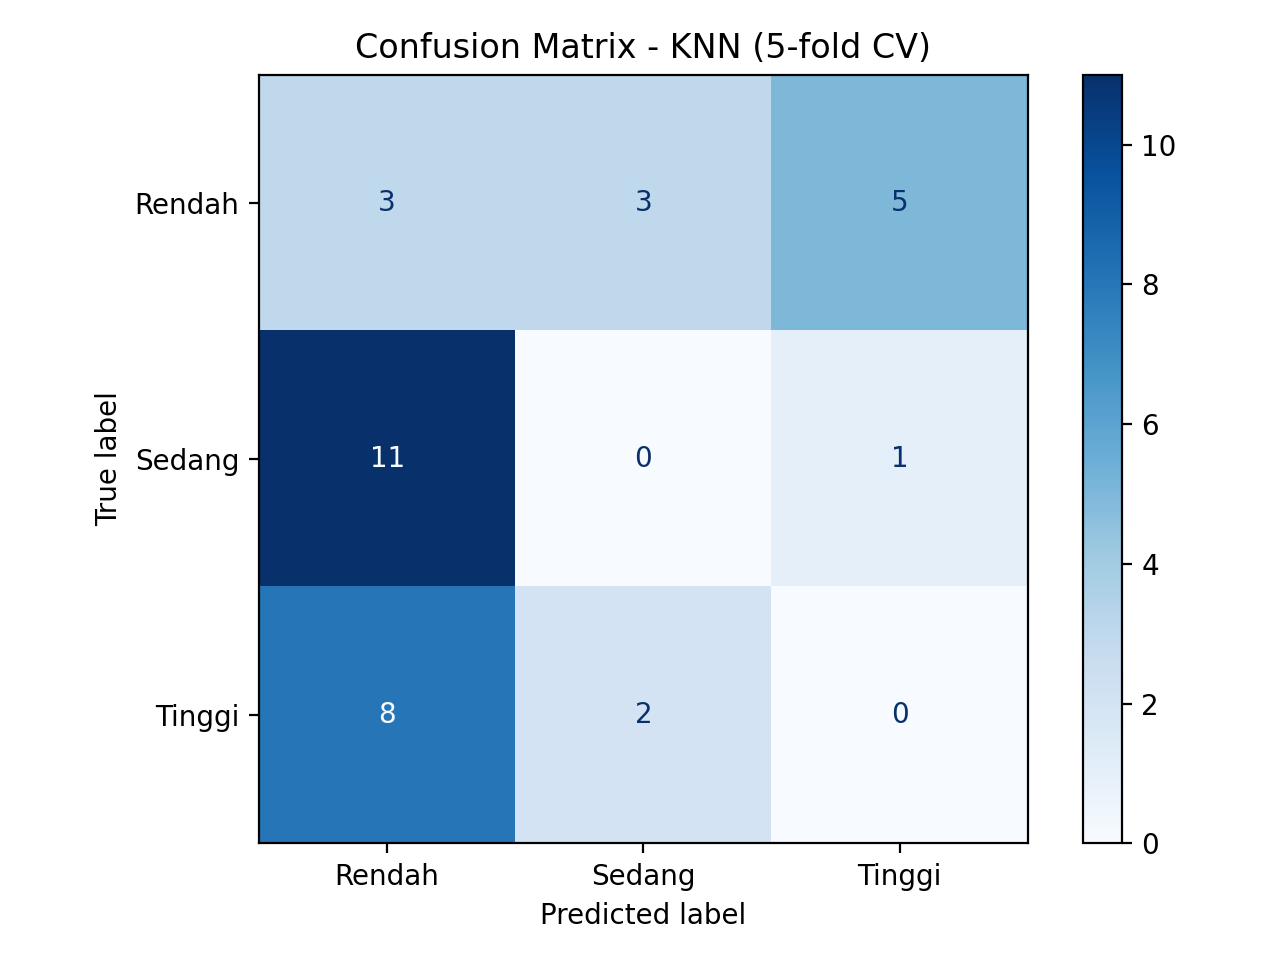

KNN
              precision    recall  f1-score   support

      Rendah       0.14      0.27      0.18        11
      Sedang       0.00      0.00      0.00        12
      Tinggi       0.00      0.00      0.00        10

    accuracy                           0.09        33
   macro avg       0.05      0.09      0.06        33
weighted avg       0.05      0.09      0.06        33



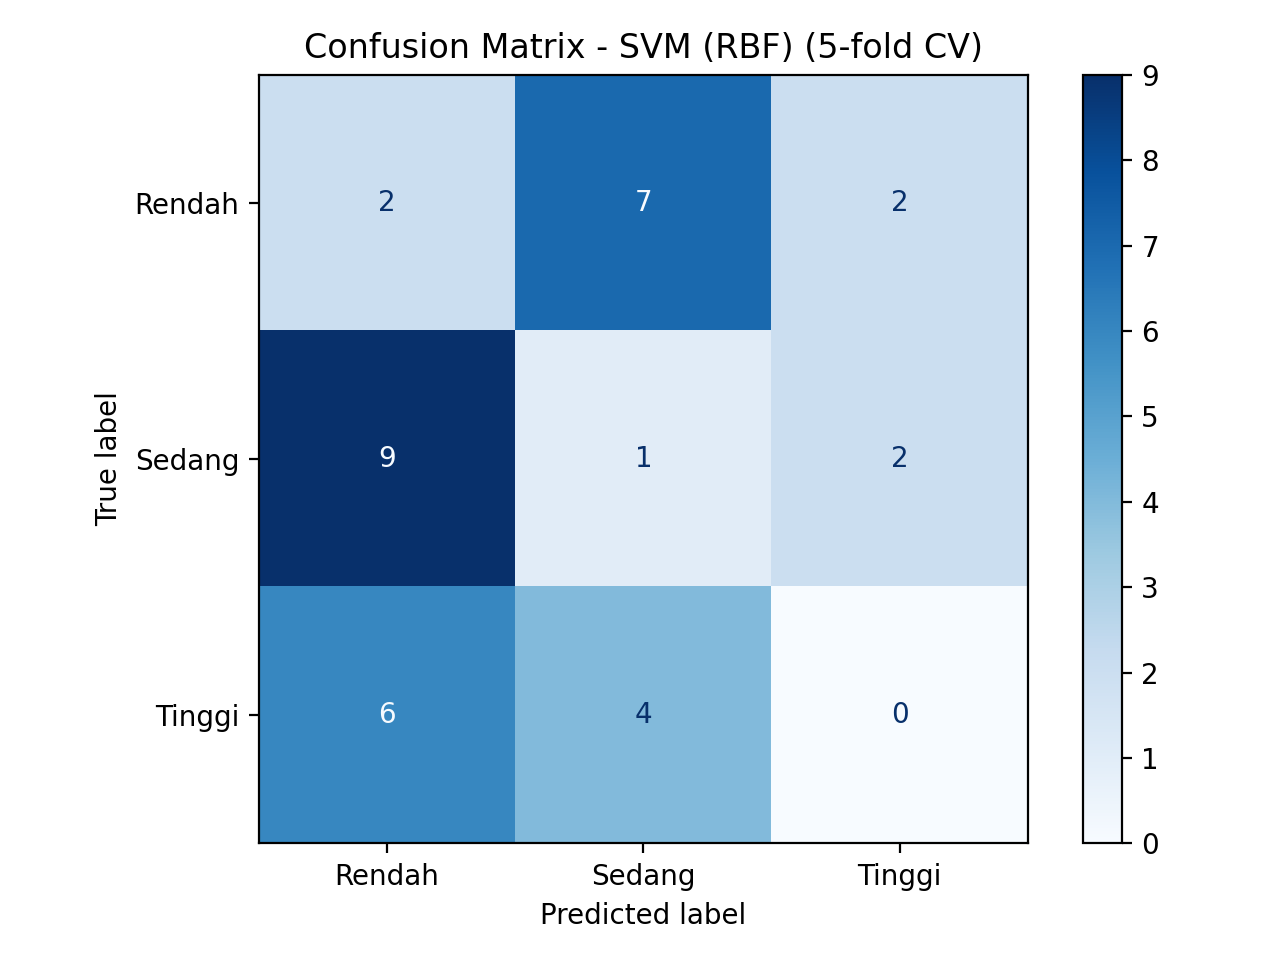

SVM (RBF)
              precision    recall  f1-score   support

      Rendah       0.12      0.18      0.14        11
      Sedang       0.08      0.08      0.08        12
      Tinggi       0.00      0.00      0.00        10

    accuracy                           0.09        33
   macro avg       0.07      0.09      0.08        33
weighted avg       0.07      0.09      0.08        33



In [22]:
import os
import pandas as pd
from IPython.display import Image, display

OUT = "hasil"
PILIH = ["knn", "svm"]          # samakan dengan Cell 2
NAMA = {"knn": "KNN", "svm": "SVM (RBF)", "nb": "Naive Bayes", "tree": "Decision Tree"}

print("Isi folder hasil:", os.listdir(OUT))
display(pd.read_csv(f"{OUT}/perbandingan.csv").round(3))
for k in PILIH:
    display(Image(f"{OUT}/cm_{k}.png"))
    print(NAMA[k]); print(open(f"{OUT}/report_{k}.txt").read())

In [23]:
%%writefile app.py
import json, joblib, pandas as pd, streamlit as st

st.set_page_config(page_title="Demo Klasifikasi Sumut")
meta = json.load(open("hasil/meta.json")); model = joblib.load("hasil/model.joblib")
st.title("Demo Prediksi - Dataset Lokal Sumut")
st.caption(f"Model: {meta['model']} | Target: {meta['target']}")
inp = {}
for c, (lo, hi, med) in meta["numeric"].items():
    inp[c] = st.number_input(c, value=float(med), min_value=float(lo), max_value=float(hi))
for c, opts in meta["categorical"].items():
    inp[c] = st.selectbox(c, opts)
if st.button("Prediksi"):
    X = pd.DataFrame([inp]); pred = model.predict(X)[0]
    st.success(f"Prediksi: **{pred}**")
    if hasattr(model, "predict_proba"):
        st.bar_chart(pd.Series(model.predict_proba(X)[0], index=model.classes_))
st.info("Catatan etika: model dilatih dari data terbatas; jangan dipakai untuk keputusan yang mendiskriminasi.")

Writing app.py


In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared
!pkill -f streamlit || true
!streamlit run app.py --server.port 8501 --server.headless true --server.enableCORS false --server.enableXsrfProtection false &>/content/log.txt &
import time; time.sleep(5)
!./cloudflared tunnel --url http://localhost:8501

^C
2026-10-27T16:26:29Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-27T16:26:29Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-27T16:26:32Z INF +--------------------------------------------------------------------------------------------+
2026-10-27T16:26:32Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-27T16:26:32Z INF |  https://species-kentucky-pursuit-using.trycloudfla

In [ ]:
import shutil
from google.colab import files
shutil.make_archive("hasil", "zip", "hasil")
files.download("hasil.zip")